# Tentativo 14 · 1. Preparazione del dataset

**Obiettivo**: un dataset di articoli di testate **solo politiche**, ognuna con il suo livello NewsGuard 2026, diviso
in 5 fold in modo che testate "parenti" (stessa rete, stesso proprietario) non finiscano una nel training e una nel test.

Partiamo dai dati grezzi dello scraping e li puliamo un passo alla volta: dopo ogni passo vediamo quanti articoli e
testate restano. Alla fine il dataset deve essere identico a quello del tentativo 13.

In [1]:
N_JOBS = 32       # processi in parallelo
TESTATE = 0       # 0 = tutte; un numero = prova veloce su quel numero di testate a caso

In [2]:
import hashlib
import itertools
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.lines import Line2D
from sklearn.model_selection import StratifiedGroupKFold

import funzioni as F                     # le funzioni lunghe (lingua, copie, reti), prese dai tentativi precedenti

warnings.filterwarnings("ignore")
DATI = Path("Dataset")
GIRI = [DATI / "NuovoScraping_ottobre", DATI / "NuovoScraping_giro3"]     # lo scraping di ottobre 2026 (tutti i giri)
OUT = Path("Results/dataset") / ("prova" if TESTATE else "")
GRAFICI = OUT / "grafici"; GRAFICI.mkdir(parents=True, exist_ok=True)

# colori: blu = si tiene, arancio = si toglie; livelli NewsGuard dal rosso (l1, inaffidabile) al blu (l5)
BLU, ARANCIO, VERDE, GRIGIO, CHIARO = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#b5b3ab"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
    "patch.force_edgecolor": True, "patch.edgecolor": "#fcfcfb", "patch.linewidth": 0.6,
})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 100)

passi = []
def passo(nome, df):
    """Annota e stampa quanti articoli e testate restano dopo un passo."""
    tolti = passi[-1]["articoli"] - len(df) if passi else 0
    passi.append({"passo": nome, "articoli": len(df), "testate": df.domain.nunique()})
    print(f"→ restano {len(df):,} articoli di {df.domain.nunique():,} testate (tolti {tolti:,} articoli)")

def mostra(nome, griglia="y"):
    """Mostra il grafico (griglia solo sull'asse dei valori) e lo salva anche in PNG, per le slide."""
    for a in plt.gcf().axes:
        a.grid(False); a.grid(axis=griglia)
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

def barre(serie, titolo, nome, colore=BLU, figsize=(8, 2.6)):
    """Barre orizzontali con il numero scritto in fondo a ogni barra."""
    serie = serie[::-1]
    plt.figure(figsize=figsize); plt.barh(serie.index, serie, color=colore)
    for y, v in enumerate(serie):
        plt.text(v, y, f" {v:,}", va="center", fontsize=8, color=GRIGIO)
    plt.title(titolo); plt.gca().xaxis.set_major_formatter("{x:,.0f}"); mostra(nome, "x")

## 1. Da dove partiamo

**NewsGuard 2026** valuta migliaia di testate. A ottobre 2026 abbiamo fatto lo scraping di una parte di queste (usiamo
solo questo scraping, niente dei vecchi): per ogni testata fino a 200 articoli, con testo, titolo, data, autore e la
pagina HTML.

In [3]:
# 1.1 le etichette NewsGuard 2026 e com'è andato lo scraping (un file di stato per testata)
n26, n22 = F.leggi_newsguard(DATI / "newsguard_2026.csv"), F.leggi_newsguard(DATI / "newsguard_2022.csv")
stati = pd.concat([F.leggi_stati([g]) for g in GIRI], ignore_index=True)
if TESTATE:                                   # prova veloce: metà testate a caso, metà tra le solo politiche (per vedere i gruppi)
    politiche = stati.dominio[stati.dominio.map(n26.Topics).eq(F.POLITICA)]
    scelte = set(stati.dominio.sample(TESTATE // 2, random_state=F.SEED)) | set(politiche.sample(TESTATE // 2, random_state=F.SEED))
    stati = stati[stati.dominio.isin(scelte)]

In [4]:
# 1.2 i testi estratti: una riga per articolo
grezzo = F.leggi_scraping(GIRI, stati.dominio if TESTATE else None).rename(columns={"dominio": "domain", "testo": "text"})
grezzo[["domain", "titolo", "data", "parole", "text"]].sample(3, random_state=1).assign(text=lambda d: d.text.str[:80] + " …")

,domain,titolo,data,parole,text
250303,thelastpatriotnews.com,BOMBSHELL: Bloody Prints Don’t Match,2026-10-18,845,"A blood-smeared rum bottle, a vulgar note, and a 14-year wait now hinge on a han …"
131404,lbc.co.uk,Northern lights illuminate UK skies as far down as England's south coast | LBC,2026-10-11,287,Northern lights illuminate UK skies as far down as England's south coast\nSightin …
4727,affarinternazionali.it,Tensioni tra Israele e Hezbollah - Affarinternazionali,2024-07-30,88,In questo podcast vi proponiamo l’intervento di Maria Luisa Fantappiè (Responsab …


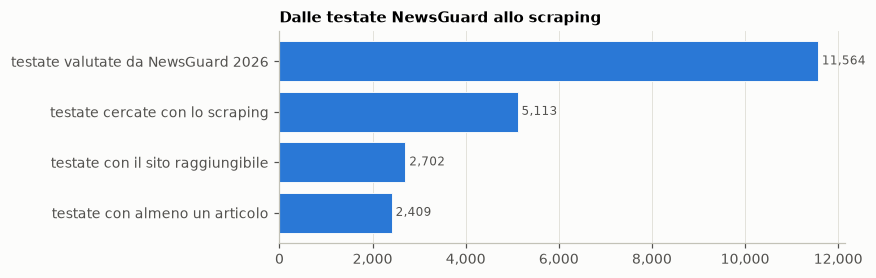

→ restano 299,658 articoli di 2,409 testate (tolti 0 articoli)


In [5]:
# 1.3 dalle testate di NewsGuard agli articoli: quante ne restano a ogni tappa
barre(pd.Series({"testate valutate da NewsGuard 2026": n26.Score.notna().sum(),
                 "testate cercate con lo scraping": len(stati),
                 "testate con il sito raggiungibile": (~stati.esito.str.startswith("homepage")).sum(),
                 "testate con almeno un articolo": grezzo.domain.nunique()}), "Dalle testate NewsGuard allo scraping", "1_testate")
passo("1.3 testi estratti dallo scraping", grezzo)

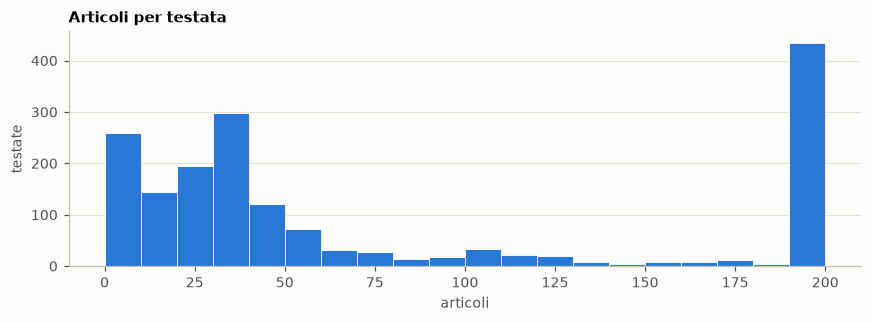

In [6]:
# 1.4 quanti articoli per testata (al più 200)
plt.hist(grezzo.groupby("domain").size(), bins=np.arange(0, 210, 10), color=BLU)
plt.title("Articoli per testata"); plt.xlabel("articoli"); plt.ylabel("testate")
mostra("1_articoli_per_testata")

## 2. La pulizia degli articoli

Prima togliamo gli articoli che non ci servono: troppo corti, doppi, non in inglese, troppo vecchi.

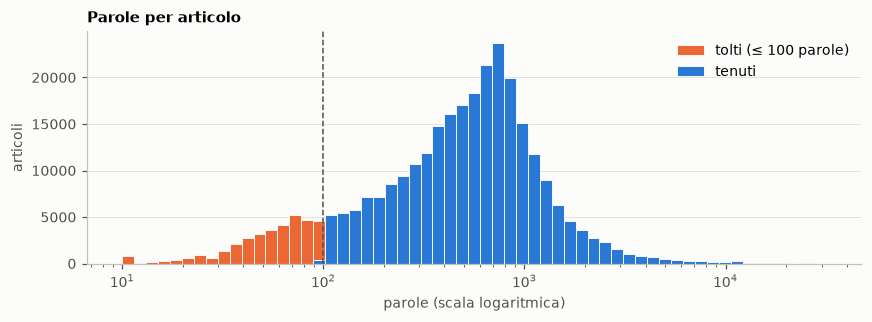

→ restano 264,203 articoli di 2,381 testate (tolti 35,455 articoli)


In [7]:
# 2.1 via gli articoli corti (≤ 100 parole): pagine di servizio, didascalie, brevi
bins = np.logspace(1, 4.5, 60)
plt.hist(grezzo.parole[grezzo.parole <= 100].clip(lower=10), bins, color=ARANCIO, label="tolti (≤ 100 parole)")
plt.hist(grezzo.parole[grezzo.parole > 100], bins, color=BLU, label="tenuti")
plt.xscale("log"); plt.axvline(100, color=GRIGIO, ls="--", lw=1)
plt.title("Parole per articolo"); plt.xlabel("parole (scala logaritmica)"); plt.ylabel("articoli"); plt.legend()
mostra("2_parole")

art = grezzo[grezzo.parole > 100]
passo("2.1 più di 100 parole", art)

In [8]:
# 2.2 via i doppioni nella stessa testata: stesso URL o stesso testo
art = art.drop_duplicates(["domain", "url"]).drop_duplicates(["domain", "text"])
passo("2.2 senza stesso URL o stesso testo", art)

→ restano 264,125 articoli di 2,381 testate (tolti 78 articoli)


Molte testate (e molti articoli) non sono in inglese: riconosciamo la lingua di ogni articolo e teniamo l'inglese.

In [9]:
# 2.3 la lingua di ogni articolo (riconoscimento automatico sulle prime 400 parole)
art = art.assign(lingua=Parallel(n_jobs=N_JOBS, batch_size=200)(delayed(F.lingua)(t) for t in art.text))
display(art.lingua.value_counts().head(8).rename("articoli").to_frame().T)

art = art[art.lingua == "en"].reset_index(drop=True).rename_axis("article_id").reset_index()   # da qui ogni articolo ha un numero
base = art.copy()                     # gli articoli in inglese di partenza: servono per le frasi ripetute (2.6) e le reti (3)
passo("2.3 solo inglese", art)

lingua,en,de,it,fr,ru,es,vi,pt
articoli,189189,33423,18115,16824,1819,1513,439,428


→ restano 189,189 articoli di 1,957 testate (tolti 74,936 articoli)


In [10]:
# 2.4 lo stesso testo due volte nella stessa testata, anche con maiuscole o punteggiatura diverse: si tiene il più vecchio
art["data"] = pd.to_datetime(art.data, errors="coerce")
art["norm"] = art.text.map(F.normalizza)                         # minuscole, solo lettere e cifre, spazi singoli
art["impronta"] = art.norm.map(lambda s: hashlib.md5(s.encode()).hexdigest())
art = art.sort_values("data").drop_duplicates(["domain", "impronta"]).sort_index()
inglese = art.copy()                  # tutti gli articoli in inglese, di ogni data: qui dentro cerchiamo le copie tra testate (3.1)
passo("2.4 senza copie identiche nella testata", art)

→ restano 189,158 articoli di 1,957 testate (tolti 31 articoli)


In [11]:
# 2.5 solo articoli dal 2025: il periodo delle etichette NewsGuard 2026
anno = art.data.dt.year
per_anno = anno[anno >= 2015].astype(int).value_counts().sort_index()
display(pd.concat([pd.Series({"senza data": anno.isna().sum(), "prima del 2015": (anno < 2015).sum()}), per_anno]).rename("articoli").to_frame().T)
art = art[art.data >= "2025-01-01"]
passo("2.5 pubblicati dal 2025", art)

,senza data,prima del 2015,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
articoli,4,5753,821,1206,1723,1919,2556,2377,2858,4641,5021,11109,10303,138867


→ restano 149,170 articoli di 1,819 testate (tolti 39,988 articoli)


Ora puliamo il **testo** degli articoli rimasti. Il sito aggiunge pezzi sempre uguali (firme, inviti a donare, titolo,
data, link): non dicono nulla sull'articolo ma fanno **riconoscere il sito**, e un modello potrebbe imparare quelli.

In [12]:
# 2.6 frasi che la stessa testata ripete in almeno 3 articoli: firme, inviti a donare o iscriversi, piè di pagina
tutti = base[["domain", "text"]].assign(norm=base.text.map(F.normalizza)).drop_duplicates(["domain", "norm"])
parole_prima = art.text.str.split().str.len().sum()
testi, esempi = F.togli_frasi_ripetute(art, tutti)            # le ripetizioni si contano su tutti gli articoli della testata
art = art.assign(text=testi)
print(f"parole tolte: {1 - art.text.str.split().str.len().sum() / parole_prima:.1%}")
pd.DataFrame(esempi, columns=["articoli", "testata", "frase ripetuta (esempio)"]).set_index("testata")

parole tolte: 4.9%


,articoli,frase ripetuta (esempio)
testata,,
truthout.org,200,we lost 15 percent of our readership overnight
truth-out.org,200,we lost 15 percent of our readership overnight
thewest.com.au,200,get the latest news from thewest com au in your inbox
thewellnews.com,200,we re proud to make our journalism accessible to everyone but producing high quality journalism ...
theroot.com,200,sign up for our free daily newsletter
thedailybeast.com,200,substack access provided by the next business day using your subscription email
steadfastandloyal.com,200,if your comment doesn t post submit another comment right after it that says jimmy please approv...
spiked-online.com,200,support spiked and get unlimited access
spencerfernando.com,200,spencer fernando s writing is now on substack


In [13]:
# 2.7 titolo e data ripetuti all'inizio del testo
prima = art.text
esiti = [F.togli_cornice(t, ti) for t, ti in zip(art.text, art.titolo.fillna(""))]
art = art.assign(text=[e[0] for e in esiti])
print(f"titolo tolto: {sum(e[1] for e in esiti):,} articoli; data tolta: {sum(e[2] for e in esiti):,} articoli\n")

i = ([i for i, e in zip(art.index, esiti) if e[1] and e[2]] or [i for i, e in zip(art.index, esiti) if e[1]])[0]   # un esempio
print("PRIMA:", prima[i][:230].replace("\n", " ⏎ "), "…")
print("DOPO: ", art.text[i][:150].replace("\n", " ⏎ "), "…")

titolo tolto: 36,724 articoli; data tolta: 4,352 articoli

PRIMA: How the fossil fuel industry ‘captured’ Australia and maintains its political dominance ⏎ Published on October 15, 2026 ⏎ By framing coal and gas as essential to jobs, prosperity and national identity, the industry continues to resist …
DOPO:  By framing coal and gas as essential to jobs, prosperity and national identity, the industry continues to resist the transition to renewable energy. ⏎ A …


In [14]:
# 2.8 link, firme dei tweet incorporati e scritte dei post incorporati ("View this post on Instagram")
prima = art.text
art = art.assign(text=art.text.map(F.togli_incorporati))
print(f"articoli toccati: {(art.text != prima).sum():,}; caratteri tolti: {1 - art.text.str.len().sum() / prima.str.len().sum():.2%}")

esempi, cambiati = [], art[art.text != prima].drop_duplicates("domain")        # una testata per esempio
for i in cambiati.sample(min(8, len(cambiati)), random_state=3).index:
    riga = [r for r in prima[i].split("\n") if r not in art.text[i]][0]
    esempi.append((art.domain[i], (F.LINK.findall(riga) or [riga])[0][:90]))     # il link, oppure la riga intera
pd.DataFrame(esempi, columns=["testata", "tolto (esempio)"]).set_index("testata")

articoli toccati: 24,220; caratteri tolti: 0.44%


,tolto (esempio)
testata,
pjmedia.com,"— Spencer Pratt (@spencerpratt) October 17, 2026"
australiannationalreview.com,https://t.co/e4dzo7sUWv
thescarboroughnews.co.uk,www.tickettailor.com/events/harbourside/2385420
frontpagemag.com,pic.twitter.com/PBZTsWqlSL
tivysideadvertiser.co.uk,https://bit.ly/DPPmissingperson.
racewar.news,https://www.lewrockwell.com/2025/05/no_author/the-dojs-assault-on-white-christians-is-wors
rsbnetwork.com,https://rumble.com/v7gthvw-praying-for-america-w-father-frank-how-we-win-the-midterms-1013
paulcraigroberts.org,https://www.instagram.com/reel/De2icW8DEPb/?rpxt=MTlzNTA0Y21uMTJjbw==


In [15]:
# 2.9 articoli quasi uguali nella stessa testata (aggiornamenti dello stesso pezzo): si tiene il più vecchio
art["norm"] = art.text.map(F.normalizza)
art, n = F.togli_doppioni_in_testata(art.reset_index(drop=True), 0.5, N_JOBS)
passo("2.9 senza quasi doppioni nella testata", art)

→ restano 148,331 articoli di 1,819 testate (tolti 839 articoli)


In [16]:
# 2.10 dopo la pulizia devono restare almeno 100 parole
art = art[art.text.str.split().str.len() >= 100]
passo("2.10 almeno 100 parole dopo la pulizia", art)

→ restano 143,106 articoli di 1,816 testate (tolti 5,225 articoli)


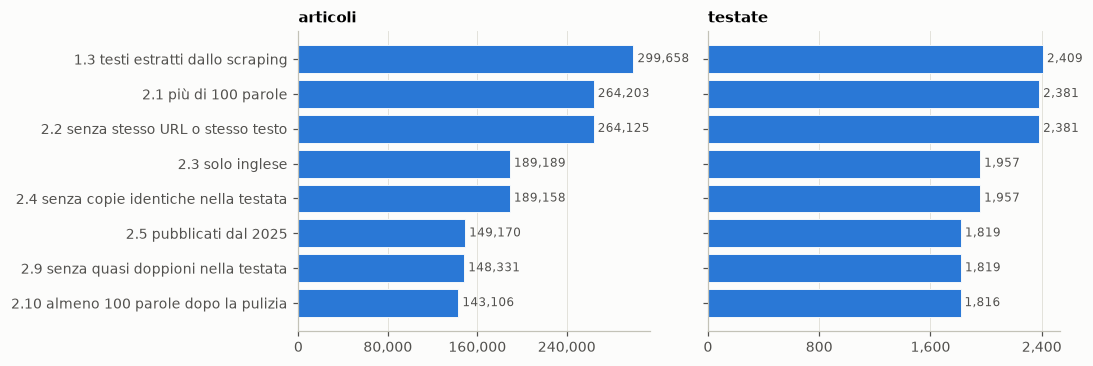

In [17]:
# la pulizia in un colpo d'occhio
p = pd.DataFrame(passi).set_index("passo")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, col in zip(ax, ["articoli", "testate"]):
    a.barh(p.index[::-1], p[col][::-1], color=BLU)
    a.set_title(col); a.xaxis.set_major_formatter("{x:,.0f}"); a.xaxis.set_major_locator(plt.MaxNLocator(4))
    for y, v in enumerate(p[col][::-1]):
        a.text(v, y, f" {v:,}", va="center", fontsize=8, color=GRIGIO)
mostra("2_riassunto", "x")

## 3. Copie tra testate e reti di siti

Alcune testate pubblicano gli stessi articoli, o sono siti fatti dalla stessa gente con lo stesso modello. Se una sta
nel training e l'altra nel test, il modello riconosce la "famiglia" invece dell'affidabilità. Le cerchiamo noi, dai
siti, **senza guardare le etichette**: prima le copie, poi le altre tracce.

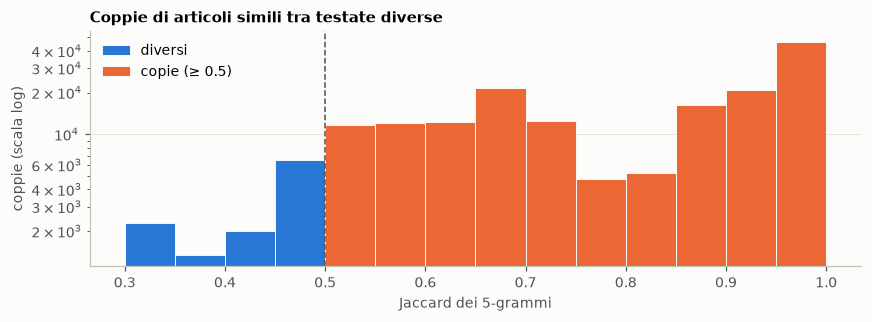

coppie di copie: 323,640; testate coinvolte: 1,434


In [18]:
# 3.1 articoli copiati tra testate diverse: somiglianza (Jaccard dei 5-grammi di parole) >= 0.5, su tutti gli articoli in inglese
coppie = F.coppie_simili(inglese.reset_index(drop=True), 0.3, N_JOBS)          # tutte le coppie sopra 0.3, per il grafico
tra = coppie[coppie.testata_a != coppie.testata_b]
copie = tra[tra.jaccard >= 0.5]

bins = np.arange(0.3, 1.0001, 0.05)
plt.hist(tra.jaccard[tra.jaccard < 0.5], bins, color=BLU, label="diversi")
plt.hist(copie.jaccard, bins, color=ARANCIO, label="copie (≥ 0.5)")
plt.yscale("log"); plt.axvline(0.5, color=GRIGIO, ls="--", lw=1); plt.legend()
plt.title("Coppie di articoli simili tra testate diverse"); plt.xlabel("Jaccard dei 5-grammi"); plt.ylabel("coppie (scala log)")
mostra("3_copie")
print(f"coppie di copie: {len(copie):,}; testate coinvolte: {len(set(copie.testata_a) | set(copie.testata_b)):,}")

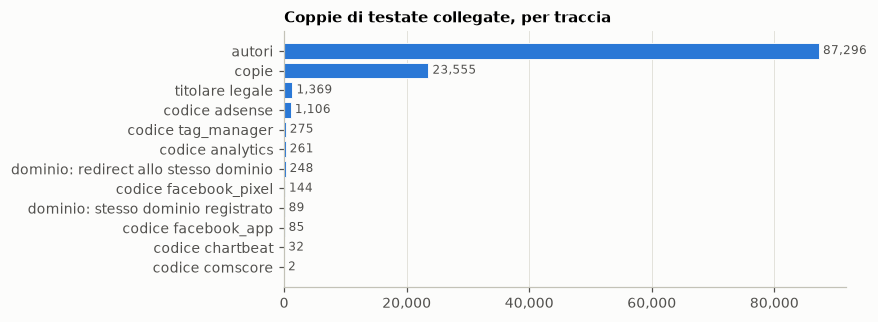

In [19]:
# 3.2 due testate sono collegate se condividono una traccia: copie (3.1), codici di account (pubblicità, statistiche),
#     titolare legale (privacy policy esterna), dominio o redirect, autori
rete, collegamenti, per_segnale = F.reti_di_testate(base[["article_id", "domain", "autore"]], copie, GIRI,
                                                     DATI / "disconnect_services.json", N_JOBS)
barre(pd.Series(per_segnale).sort_values(ascending=False), "Coppie di testate collegate, per traccia", "3_tracce", figsize=(8, 3))

In [20]:
# 3.3 una rete = testate collegate, anche indirettamente (A–B e B–C: A, B e C nella stessa rete)
reti = pd.Series(rete, name="rete").rename_axis("domain")
dimensione = reti.map(reti.value_counts())
print(f"{reti.nunique():,} reti; testate in una rete con altre: {(dimensione > 1).sum():,} su {len(reti):,}")
pd.DataFrame([{"testate": n, "esempi": ", ".join(sorted(reti.index[reti == r])[:5]) + ", …"}
              for r, n in reti.value_counts().head(5).items()])

683 reti; testate in una rete con altre: 1,381 su 1,957


,testate,esempi
0,534,"5galert.com, abortions.news, absurd.news, activeshooter.news, activistpost.com, …"
1,191,"alloaadvertiser.com, ardrossanherald.com, asianimage.co.uk, ayradvertiser.com, ballymenatimes.co..."
2,161,"24usnews.com, africdaily.com, alexadaily.com, allcitytimes.com, annatimes.com, …"
3,40,"alabamanow.com, americustimesrecorder.com, amnews.com, bogalusadailynews.com, capitol-beat.org, …"
4,33,"conservativecore.com, conservativefreepress.com, conservativehub.com, dcwatchdog.com, fixthisnat..."


## 4. Solo testate politiche

Il dataset è **solo politico**: teniamo le testate che per NewsGuard 2026 hanno **un solo argomento**,
"Political news or commentary". Chi ha più argomenti (per esempio politica + salute) resta fuori.

In [21]:
# 4.1 gli argomenti di ogni testata secondo NewsGuard 2026
argomenti = art.domain.map(n26.Topics).fillna("").str.split(",").map(lambda x: [a.strip() for a in x if a.strip()])
art["score"] = art.domain.map(n26.Score)
art["tipo"] = np.select([art.score.isna(), argomenti.map(lambda x: x == [F.POLITICA]), argomenti.map(lambda x: F.POLITICA in x)],
                        ["senza punteggio 2026", "solo politica", "politica e altri argomenti"], "altri argomenti")
art.groupby("tipo").agg(testate=("domain", "nunique"), articoli=("domain", "size")).sort_values("testate", ascending=False)

,testate,articoli
tipo,,
politica e altri argomenti,1137,78147
solo politica,532,43728
altri argomenti,117,17042
senza punteggio 2026,30,4189


In [22]:
# 4.2 le combinazioni di argomenti più frequenti tra le testate che escono
per_testata = pd.DataFrame({"domain": art.domain, "tipo": art.tipo, "argomenti": argomenti.str.join(" + ")}).drop_duplicates("domain")
per_testata[(per_testata.tipo != "solo politica") & (per_testata.argomenti != "")].argomenti.value_counts().head(6).rename("testate").to_frame()

,testate
argomenti,
Health or medical information + Political news or commentary + Conspiracy theories or hoaxes,505
Political news or commentary + Business or Personal Finance,158
Political news or commentary + General News,146
Local News + General News,53
Local News,47
Political news or commentary + Conspiracy theories or hoaxes,29


In [23]:
# 4.3 teniamo solo le testate "solo politica"; l'etichetta è il livello dal punteggio NewsGuard 2026
art = art[art.tipo == "solo politica"].copy()
art["label"] = F.livello(art.score)                   # 0..4 = l1..l5
art["livello"] = art.label.map(dict(enumerate(F.LIVELLI)))
passo("4.3 solo politici, con punteggio 2026", art)

→ restano 43,728 articoli di 532 testate (tolti 99,378 articoli)


In [24]:
# 4.4 quante testate e articoli per livello (binario: affidabile se punteggio >= 60, cioè l3–l5)
pd.DataFrame({"punteggio": ["0–39", "40–59", "60–74", "75–99", "100"], "affidabile": ["no", "no", "sì", "sì", "sì"],
              "testate": art.groupby("livello").domain.nunique(), "articoli": art.groupby("livello").size()}, index=F.LIVELLI)

,punteggio,affidabile,testate,articoli
l1,0–39,no,220,8360
l2,40–59,no,108,12612
l3,60–74,sì,44,4949
l4,75–99,sì,111,11753
l5,100,sì,49,6054


## 5. I gruppi: le nostre reti + NewsGuard

Un **gruppo** sta tutto nel training o tutto nel test. Alle nostre reti (3) aggiungiamo quello che sa NewsGuard (2022
e 2026): **stesso proprietario** (Owner) o **stesso Parent Domain**. È un grafo: un nodo per testata, un arco tra due
testate "parenti"; un gruppo = testate collegate, anche indirettamente. Aggiungiamo gli archi una fonte alla volta.

In [25]:
# 5.1 i nodi: tutte le testate in inglese, anche le non politiche (possono fare da ponte tra due testate politiche)
G = nx.Graph()
G.add_nodes_from(sorted(set(art.domain) | set(rete)))
politiche = sorted(art.domain.unique())
collegate = {}                         # quante testate politiche sono collegate ad altre politiche, dopo ogni fonte

def in_compagnia():
    """Quante testate politiche sono collegate (anche indirettamente) ad almeno un'altra testata politica."""
    componente = {d: i for i, c in enumerate(nx.connected_components(G)) for d in c}
    quante = pd.Series([componente[d] for d in politiche]).value_counts()
    return int(quante[quante > 1].sum())

print(f"{G.number_of_nodes():,} testate, di cui {len(politiche)} politiche; ancora nessun arco")

1,957 testate, di cui 532 politiche; ancora nessun arco


In [26]:
# 5.2 archi dalle nostre reti: testate della stessa rete
for membri in reti.groupby(reti).groups.values():
    G.add_edges_from(zip(list(membri), list(membri)[1:]))
collegate["nostre reti"] = in_compagnia()
print(f"testate politiche collegate ad altre politiche: {collegate['nostre reti']} su {len(politiche)}")

testate politiche collegate ad altre politiche: 309 su 532


In [27]:
# 5.3 archi da NewsGuard: stesso proprietario (nome normalizzato: senza "Inc", "LLC", "Media", ...)
owner = {}
for anno, ng in [(2022, n22), (2026, n26)]:
    owner[anno] = pd.Series({d: F.normalizza_owner(ng.Owner.get(d, "")) for d in G.nodes})
    o = owner[anno][owner[anno] != ""]
    for _, membri in o.groupby(o):
        G.add_edges_from(zip(membri.index, membri.index[1:]))
collegate["+ stesso owner"] = in_compagnia()
print(f"testate politiche collegate ad altre politiche: {collegate['+ stesso owner']} su {len(politiche)}")

o = owner[2026][politiche]; o = o[o != ""]                      # i proprietari (2026) con più testate politiche
pd.DataFrame([{"owner": k, "testate politiche": n, "esempi": ", ".join(o.index[o == k][:4])} for k, n in o.value_counts().head(5).items() if n > 1])

testate politiche collegate ad altre politiche: 324 su 532


,owner,testate politiche,esempi
0,fivezero,18,"beyondnews.org, conservativecardinal.com, freshoffthepress.org, mainstpress.com"
1,american independent,15,"alaskaindependentnews.com, americanindependent.com, arizonaindependent.com, floridaindependentne..."
2,good information,15,"cardinalpine.com, coppercourier.com, couriercalifornia.com, couriergeorgia.com"
3,salem,9,"hotair.com, pjmedia.com, redstate.com, redstatemail.com"
4,ryan mauldin,6,"americanjournaldaily.com, gopdailybrief.com, patriotjournal.org, pjnewsletter.com"


In [28]:
# 5.4 archi da NewsGuard: stesso Parent Domain (il sito "madre" della testata)
parent = {}
for anno, ng in [(2022, n22), (2026, n26)]:
    parent[anno] = pd.Series({d: str(ng["Parent Domain"].get(d, "")).strip().lower() for d in G.nodes}).replace("nan", "")
    p = parent[anno][parent[anno] != ""]
    for _, membri in p.groupby(p):
        G.add_edges_from(zip(membri.index, membri.index[1:]))
collegate["+ stesso Parent Domain"] = in_compagnia()
print(f"testate politiche collegate ad altre politiche: {collegate['+ stesso Parent Domain']} su {len(politiche)}")

p = parent[2026][politiche]; p = p[p != ""]                     # i Parent Domain (2026) con più testate politiche
pd.DataFrame([{"parent domain": k, "testate politiche": n, "esempi": ", ".join(p.index[p == k][:4])} for k, n in p.value_counts().head(5).items() if n > 1])

testate politiche collegate ad altre politiche: 327 su 532


,parent domain,testate politiche,esempi
0,charmdaily.com,164,"24usnews.com, africdaily.com, alexadaily.com, allcitytimes.com"
1,rightwinginsider.com,18,"beyondnews.org, conservativecardinal.com, freshoffthepress.org, mainstpress.com"
2,tainews.com,15,"alaskaindependentnews.com, americanindependent.com, arizonaindependent.com, floridaindependentne..."
3,protrumpnews.com,7,"headlines.americanlookout.com, noahreport.com, prodesantisnews.com, propatriotnews.com"
4,americanjournaldaily.com,6,"americanjournaldaily.com, gopdailybrief.com, patriotjournal.org, pjnewsletter.com"


251 gruppi di testate politiche; 46 con più testate; il più grande ne ha 164


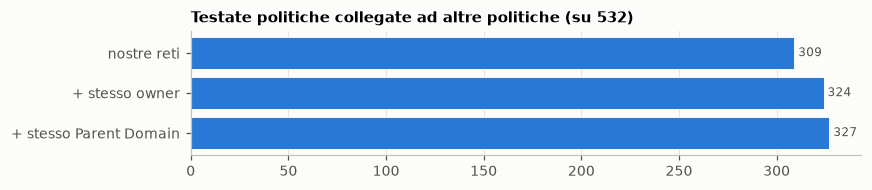

In [29]:
# 5.5 i gruppi: le componenti del grafo, numerate dalla più grande
gruppo = {d: i for i, c in enumerate(sorted(nx.connected_components(G), key=len, reverse=True)) for d in c}
art["gruppo"] = art.domain.map(gruppo)
quante = art.groupby("domain").gruppo.first().value_counts()
print(f"{len(quante)} gruppi di testate politiche; {(quante > 1).sum()} con più testate; il più grande ne ha {quante.max()}")

barre(pd.Series(collegate), f"Testate politiche collegate ad altre politiche (su {len(politiche)})", "5_fonti", figsize=(8, 1.8))

**Le nostre reti e NewsGuard dicono la stessa cosa?** A sinistra: per le nostre reti più grandi, quante testate
politiche hanno lo stesso Parent Domain (NewsGuard 2026). A destra il contrario: per i Parent Domain più grandi, in
quante delle nostre reti finiscono le loro testate.

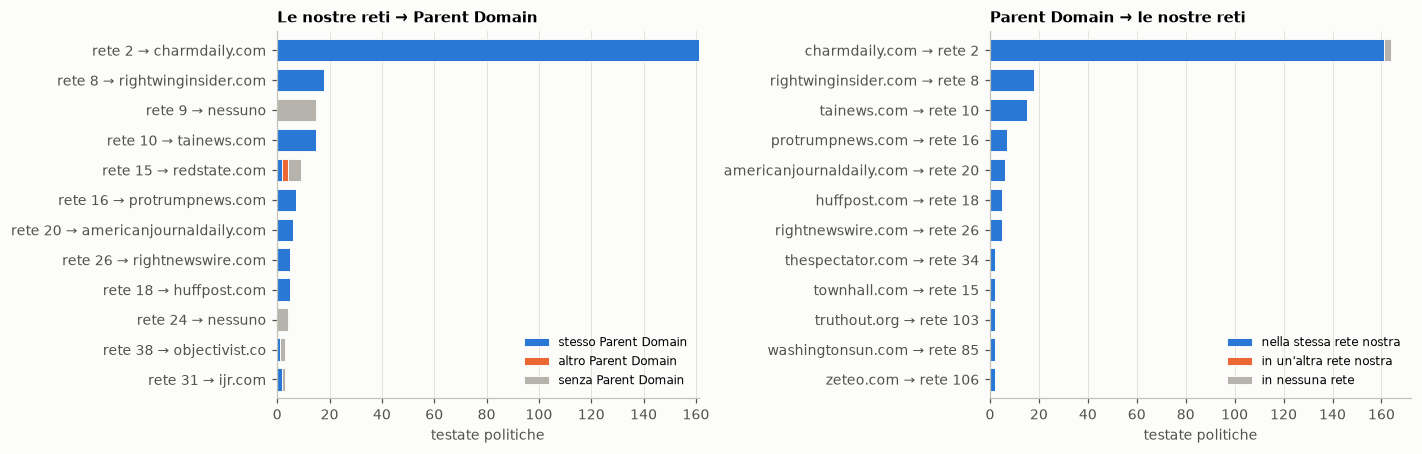

In [30]:
# 5.6 confronto tra le nostre reti e il Parent Domain di NewsGuard 2026 (solo testate politiche)
info = pd.DataFrame({"rete": reti, "owner 2022": owner[2022], "owner 2026": owner[2026],
                     "parent 2022": parent[2022], "parent 2026": parent[2026]}).loc[politiche]
info["gruppo"] = info.index.map(gruppo)
info["rete da sola"] = info.rete.map(reti.value_counts()) == 1

sinistra = []                                   # le nostre reti → Parent Domain
for r, m in info[~info["rete da sola"]].groupby("rete"):
    pdom = m["parent 2026"][m["parent 2026"] != ""].value_counts()
    principale = pdom.iloc[0] if len(pdom) else 0
    sinistra.append({"nome": f"rete {r} → {pdom.index[0] if len(pdom) else 'nessuno'}", "stesso Parent Domain": principale,
                     "altro Parent Domain": pdom.sum() - principale, "senza Parent Domain": (m["parent 2026"] == "").sum()})
destra = []                                     # Parent Domain → le nostre reti
for pdn, m in info[info["parent 2026"] != ""].groupby("parent 2026"):
    nelle_reti = m.rete[~m["rete da sola"]].value_counts()
    principale = nelle_reti.iloc[0] if len(nelle_reti) else 0
    destra.append({"nome": f"{pdn} → rete {nelle_reti.index[0] if len(nelle_reti) else '—'}", "nella stessa rete nostra": principale,
                   "in un'altra rete nostra": nelle_reti.sum() - principale, "in nessuna rete": m["rete da sola"].sum()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, righe, titolo in [(ax[0], sinistra, "Le nostre reti → Parent Domain"), (ax[1], destra, "Parent Domain → le nostre reti")]:
    tab = pd.DataFrame(righe).set_index("nome")
    tab = tab[tab.sum(axis=1) >= 2].loc[lambda x: x.sum(axis=1).sort_values().index[-12:]]
    if tab.empty:
        continue
    tab.plot.barh(stacked=True, ax=a, color=[BLU, ARANCIO, CHIARO], width=0.75)
    a.set_title(titolo); a.set_xlabel("testate politiche"); a.set_ylabel(""); a.legend(loc="lower right", fontsize=8)
mostra("5_reti_e_parent_domain", "x")

Qualche gruppo da vicino: un punto per testata politica, una linea quando due testate sono parenti, colorata da chi
lo dice (le nostre reti, NewsGuard, o entrambi).

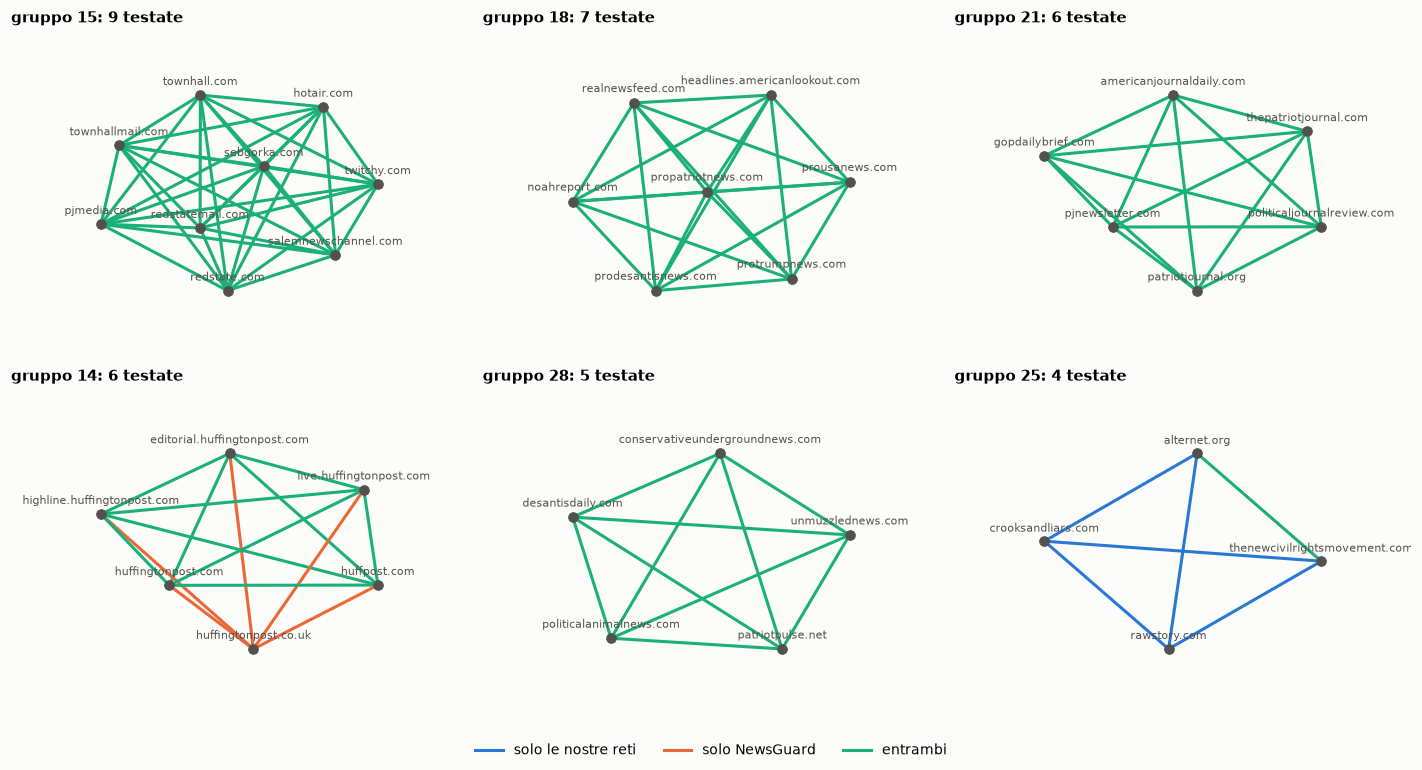

In [31]:
# 5.7 alcuni gruppi di media grandezza disegnati come grafo
def legame(a, b):
    """Chi dice che le testate a e b sono parenti: le nostre reti, NewsGuard (owner o Parent Domain), entrambi o nessuno."""
    nostre = info.rete[a] == info.rete[b]
    newsguard = any(info[c][a] != "" and info[c][a] == info[c][b] for c in ["owner 2022", "owner 2026", "parent 2022", "parent 2026"])
    return {(True, True): "entrambi", (True, False): "solo le nostre reti", (False, True): "solo NewsGuard"}.get((nostre, newsguard))

COLORE_LEGAME = {"solo le nostre reti": BLU, "solo NewsGuard": ARANCIO, "entrambi": VERDE}
quante = info.gruppo.value_counts()
esempi = ([g for g in quante.index if 3 <= quante[g] <= 10] + [g for g in quante.index if quante[g] == 2])[:6]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for a, g in zip(axes.flat, esempi):
    H = nx.Graph(); H.add_nodes_from(info.index[info.gruppo == g])
    for x, y in itertools.combinations(H.nodes, 2):
        if legame(x, y):
            H.add_edge(x, y, colore=COLORE_LEGAME[legame(x, y)])
    pos = nx.spring_layout(H, seed=1)
    nx.draw_networkx_edges(H, pos, ax=a, edge_color=[H.edges[e]["colore"] for e in H.edges], width=2)
    nx.draw_networkx_nodes(H, pos, ax=a, node_color=GRIGIO, node_size=40)
    nx.draw_networkx_labels(H, {k: (x, y + 0.13) for k, (x, y) in pos.items()}, ax=a, font_size=7, font_color=GRIGIO)
    a.set_title(f"gruppo {g}: {H.number_of_nodes()} testate"); a.margins(0.25)
for a in axes.flat:
    a.axis("off")
fig.legend([Line2D([0], [0], color=c, lw=2) for c in COLORE_LEGAME.values()], COLORE_LEGAME.keys(), ncol=3, loc="lower center")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(GRAFICI / "5_gruppi_esempio.png", dpi=200, bbox_inches="tight"); plt.show()

In [32]:
# 5.8 un testo copiato tra testate di gruppi diversi: si tiene solo la copia più vecchia (mai lo stesso testo in training e test)
art, n = F.togli_copie_tra_gruppi(art, copie)
print(f"copie tra gruppi diversi tolte: {n:,}")
passo("5.8 senza copie tra gruppi diversi", art)

copie tra gruppi diversi tolte: 198
→ restano 43,530 articoli di 532 testate (tolti 198 articoli)


## 6. Test, training e fold

**Testate valutate** (quelle su cui misuriamo i modelli): almeno 20 articoli, al più 5 per gruppo, scelte a caso. Le
altre, con almeno 10 articoli, servono **solo per il training**. Poi 5 fold: un gruppo sta tutto nello stesso fold.

In [33]:
# 6.1 una riga per testata (come nel tentativo 13 si parte da quelle con almeno 5 articoli; quelle sotto 10 escono in 6.4)
t = art.groupby("domain").agg(gruppo=("gruppo", "first"), label=("label", "first"), articoli=("article_id", "size"))
t = t[t.articoli >= 5]
t.articoli.describe().round(1).to_frame("articoli per testata").T

,count,mean,std,min,25%,50%,75%,max
articoli per testata,495.0,87.8,83.9,5.0,7.0,45.0,191.5,200.0


In [34]:
# 6.2 le testate valutate: tra quelle con almeno 20 articoli, in ordine casuale, le prime 5 di ogni gruppo
idonee = t[t.articoli >= 20].reset_index()
valutate = set(idonee.sample(frac=1, random_state=F.SEED).groupby("gruppo").head(5).domain)
t["valutazione"] = t.index.isin(valutate)
t = t.sort_index()
print(f"con almeno 20 articoli: {len(idonee)}; valutate: {len(valutate)} (al più 5 per gruppo)")

con almeno 20 articoli: 291; valutate: 254 (al più 5 per gruppo)


In [35]:
# 6.3 i fold: 5 parti di testate valutate con livelli simili (stratificati); ogni gruppo in un solo fold
val = t[t.valutazione].reset_index()
val["fold"] = 0
for i, (_, idx) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=F.SEED).split(val, val.label, val.gruppo), 1):
    val.loc[idx, "fold"] = i
fold_del_gruppo = val.groupby("gruppo").fold.first()

# i gruppi senza testate valutate (solo training) prendono un fold a caso
senza = sorted(set(t.gruppo) - set(fold_del_gruppo.index))
fold_del_gruppo = pd.concat([fold_del_gruppo, pd.Series(np.random.default_rng(F.SEED).integers(1, 6, len(senza)), index=senza)])
t["fold"] = t.gruppo.map(fold_del_gruppo).astype(int)
pd.crosstab(t[t.valutazione].fold, t[t.valutazione].label.map(dict(enumerate(F.LIVELLI))), margins=True, margins_name="totale")

label,l1,l2,l3,l4,l5,totale
fold,,,,,,
1,9,11,7,16,8,51
2,10,11,6,16,8,51
3,9,11,6,17,8,51
4,9,11,6,17,8,51
5,9,11,6,16,8,50
totale,46,55,31,82,40,254


In [36]:
# 6.4 via le testate con meno di 10 articoli; peso nel training: min(1, 5 / testate del gruppo), per non far pesare troppo i gruppi grandi
t = t[t.articoli >= 10].copy()
t["peso"] = np.minimum(1.0, 5 / t.groupby("gruppo").label.transform("size"))
art = art[art.domain.isin(t.index)].copy()
for c in ["valutazione", "fold", "peso"]:
    art[c] = art.domain.map(t[c])
passo("6.4 testate con almeno 10 articoli", art)

→ restano 42,219 articoli di 323 testate (tolti 1,311 articoli)


### Il dataset finale

In [37]:
# 6.5 testate e articoli per livello
t["livello"] = t.label.map(dict(enumerate(F.LIVELLI)))
finale = pd.DataFrame({"testate valutate": t[t.valutazione].livello.value_counts(),
                       "testate solo training": t[~t.valutazione].livello.value_counts(),
                       "articoli": art.groupby("livello").size()}).reindex(F.LIVELLI).fillna(0).astype(int)
finale.insert(2, "testate", finale["testate valutate"] + finale["testate solo training"])
finale.loc["totale"] = finale.sum()
finale.loc["binario: inaffidabili (l1–l2)"] = finale.loc[["l1", "l2"]].sum()
finale.loc["binario: affidabili (l3–l5)"] = finale.loc[["l3", "l4", "l5"]].sum()
finale

,testate valutate,testate solo training,testate,articoli
livello,,,,
l1,46,8,54,7114
l2,55,38,93,12533
l3,31,5,36,4901
l4,82,16,98,11657
l5,40,2,42,6014
totale,254,69,323,42219
binario: inaffidabili (l1–l2),101,46,147,19647
binario: affidabili (l3–l5),153,23,176,22572


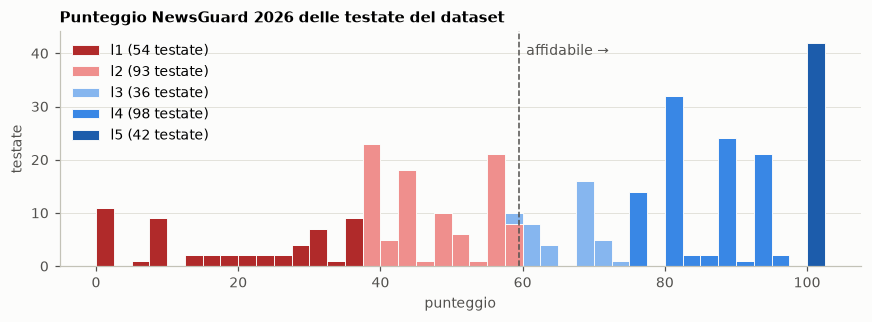

In [38]:
# i punteggi NewsGuard 2026 delle testate del dataset, colorati per livello
t["score"] = t.index.map(n26.Score)
plt.hist([t.score[t.label == k] for k in range(5)], np.arange(0, 102.6, 2.5), stacked=True, color=COLORE_LIVELLO,
         label=[f"{l} ({(t.label == k).sum()} testate)" for k, l in enumerate(F.LIVELLI)])
plt.axvline(59.5, color=GRIGIO, ls="--", lw=1); plt.text(60.5, plt.ylim()[1] * 0.9, "affidabile →", color=GRIGIO)
plt.title("Punteggio NewsGuard 2026 delle testate del dataset"); plt.xlabel("punteggio"); plt.ylabel("testate"); plt.legend()
mostra("6_punteggi")

In [39]:
# 6.6 per orientamento politico (NewsGuard 2026)
t["orientamento"] = t.index.map(n26.Orientation).fillna("nessuno")
pd.crosstab([t.valutazione.map({True: "valutate", False: "solo training"}), t.orientamento], t.livello, margins=True, margins_name="totale")

livello                     l1  l2  l3  l4  l5  totale
valutazione   orientamento                            
solo training Left           1  19   0   6   0      26
              Right          7  17   5   3   0      32
              nessuno        0   2   0   7   2      11
valutate      Left           3  15   6  38  16      78
              Right         37  36  18  25   4     120
              nessuno        6   4   7  19  20      56
totale                      54  93  36  98  42     323

In [40]:
# 6.7 controllo: deve essere lo stesso dataset del tentativo 13 (solo con tutte le testate)
if not TESTATE:
    r = pd.read_csv(DATI / "riferimento_t13_fold.csv").set_index("domain")
    v = t.index[t.valutazione]
    for nome, ok in {"stesse testate": set(r.index) == set(t.index),
                     "stesse testate valutate": set(r.index[r.valutazione]) == set(v),
                     "stesse etichette": (r.label.reindex(t.index) == t.label).all(),
                     "stessi fold delle valutate": (r.fold_gruppo.reindex(v) == t.fold[v]).all()}.items():
        print(("✓ " if ok else "✗ ") + nome)

✓ stesse testate
✓ stesse testate valutate
✓ stesse etichette
✓ stessi fold delle valutate


## 7. Salvo il dataset
Per il notebook di classificazione.

In [41]:
colonne = ["article_id", "domain", "url", "titolo", "data", "text", "label", "gruppo", "valutazione", "fold", "peso"]
art[colonne].to_csv(OUT / "articoli.csv.gz", index=False)
t.to_csv(OUT / "testate.csv")
print(f"{len(art):,} articoli di {len(t)} testate ({t.valutazione.sum()} valutate) → {OUT}/articoli.csv.gz, testate.csv")
pd.DataFrame(passi).set_index("passo")

42,219 articoli di 323 testate (254 valutate) → Results/dataset/articoli.csv.gz, testate.csv


,articoli,testate
passo,,
1.3 testi estratti dallo scraping,299658,2409
2.1 più di 100 parole,264203,2381
2.2 senza stesso URL o stesso testo,264125,2381
2.3 solo inglese,189189,1957
2.4 senza copie identiche nella testata,189158,1957
2.5 pubblicati dal 2025,149170,1819
2.9 senza quasi doppioni nella testata,148331,1819
2.10 almeno 100 parole dopo la pulizia,143106,1816
"4.3 solo politici, con punteggio 2026",43728,532
